In [1]:
# Import Library
import random, time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, models, transforms

In [2]:
# Set Random Seed
SEED = 42
NUM_CLASSES = 10
BATCH = 32
MAX_EPOCHS = 30
PATIENCE = 5

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
if device.type == "cpu":
    warnings.warn("Berjalan di CPU (sangat lambat). Pilih Runtime > Change runtime type > T4 GPU.")

Device: cuda | Tesla T4


In [3]:
# Load Dataset
raw_train = datasets.OxfordIIITPet(root="./data", split="trainval", download=True)
raw_test  = datasets.OxfordIIITPet(root="./data", split="test", download=True)

CLASS_NAMES = raw_train.classes[:NUM_CLASSES]
all_paths  = list(raw_train._images) + list(raw_test._images)
all_labels = list(raw_train._labels) + list(raw_test._labels)

idx_10 = [i for i, l in enumerate(all_labels) if l < NUM_CLASSES]
paths  = [all_paths[i] for i in idx_10]
labels = [all_labels[i] for i in idx_10]

train_i, temp_i, train_y, temp_y = train_test_split(
    range(len(paths)), labels, test_size=0.30, stratify=labels, random_state=SEED)
val_i, test_i, val_y, test_y = train_test_split(
    temp_i, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)

# Pengecekan data leakage
assert set(train_i).isdisjoint(val_i) and set(train_i).isdisjoint(test_i) and set(val_i).isdisjoint(test_i)
print(f"Total: {len(paths)} | train: {len(train_i)} | val: {len(val_i)} | test: {len(test_i)}")
print("Kelas:", CLASS_NAMES)

# Resize(256)
_pre = transforms.Resize(256)
pil_imgs = [_pre(Image.open(p).convert("RGB")) for p in paths]

class PetDataset(Dataset):
    def __init__(self, indices, transform):
        self.idx = list(indices); self.transform = transform
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return self.transform(pil_imgs[i]), labels[i]

100%|██████████| 792M/792M [00:29<00:00, 26.8MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.42MB/s]


Total: 1981 | train: 1386 | val: 297 | test: 298
Kelas: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']


In [4]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
MEAN, STD = weights.transforms().mean, weights.transforms().std

train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

# deterministic without distortion
eval_transforms = weights.transforms()

In [5]:
# Model Experiment
STRATEGY = {
    "B1": "Scratch (weights=None)",
    "B2": "Feature extraction ResNet-18 (fc only)",
    "B3": "Progressive FT: layer4 + fc, differential LR",
    "B4_NoAug": "B3 tanpa augmentasi",
    "B4_Aug": "B3 dengan augmentasi",
    "B5": "EfficientNet-B0 feature extraction (bonus)",
}

def get_model(code):
    if code == "B1":
        m = models.resnet18(weights=None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        opt = optim.AdamW([{"params": m.parameters(), "lr": 1e-3, "name": "all"}], weight_decay=1e-2)
    elif code == "B2":
        m = models.resnet18(weights=weights)
        for p in m.parameters(): p.requires_grad = False
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        opt = optim.AdamW([{"params": m.fc.parameters(), "lr": 1e-3, "name": "fc"}], weight_decay=1e-2)
    elif code in ("B3", "B4_NoAug", "B4_Aug"):
        m = models.resnet18(weights=weights)
        for p in m.parameters(): p.requires_grad = False
        for p in m.layer4.parameters(): p.requires_grad = True
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        opt = optim.AdamW([
            {"params": m.layer4.parameters(), "lr": 1e-4, "name": "layer4"},
            {"params": m.fc.parameters(),     "lr": 1e-3, "name": "fc"},
        ], weight_decay=1e-2)
    elif code == "B5":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        for p in m.parameters(): p.requires_grad = False
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        opt = optim.AdamW([{"params": m.classifier.parameters(), "lr": 1e-3, "name": "classifier"}], weight_decay=1e-2)
    else:
        raise ValueError(code)
    return m, opt

def set_frozen_bn_eval(model):
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

# Verify jumlah param yang di train
for c in ["B1", "B2", "B3", "B5"]:
    _m, _ = get_model(c)
    tp = sum(p.numel() for p in _m.parameters() if p.requires_grad)
    tt = sum(p.numel() for p in _m.parameters())
    print(f"{c}: trainable {tp:,} / {tt:,}")
    if c == "B2": assert tp == 5130
del _m

B1: trainable 11,181,642 / 11,181,642
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


B2: trainable 5,130 / 11,181,642
B3: trainable 8,398,858 / 11,181,642
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 113MB/s] 


B5: trainable 12,810 / 4,020,358


In [6]:
def make_loader(ds, shuffle, seed):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=2,
                      pin_memory=(device.type == "cuda"), generator=g, worker_init_fn=seed_worker)

def train_one_epoch(model, loader, opt, criterion):
    model.train(); set_frozen_bn_eval(model)
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        out = model(x); loss = criterion(out, y)
        loss.backward(); opt.step()
        tot += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot, probs_all, tgt_all = 0.0, [], []
    for x, y in loader:
        xd, yd = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(xd)
        tot += criterion(out, yd).item() * xd.size(0)
        probs_all.append(torch.softmax(out, 1).cpu()); tgt_all.append(y)
    probs = torch.cat(probs_all).numpy(); tgt = torch.cat(tgt_all).numpy()
    preds = probs.argmax(1)
    return tot / len(tgt), float((preds == tgt).mean()), preds, tgt, probs

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def run_exp(code, train_tf, seed=SEED):
    set_seed(seed)
    train_loader      = make_loader(PetDataset(train_i, train_tf), True, seed)
    train_eval_loader = make_loader(PetDataset(train_i, eval_transforms), False, seed)
    val_loader        = make_loader(PetDataset(val_i, eval_transforms), False, seed)
    test_loader       = make_loader(PetDataset(test_i, eval_transforms), False, seed)

    model, opt = get_model(code); model.to(device)
    criterion = nn.CrossEntropyLoss()
    trainable_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_p = sum(p.numel() for p in model.parameters())
    lr_desc = "; ".join(f"{g['name']}={g['lr']:g}" for g in opt.param_groups)
    print(f"\n[{code}] seed={seed} | trainable {trainable_p:,} / {total_p:,} | lr: {lr_desc}")

    history, best_loss, best_epoch, best_state, wait = [], float("inf"), 0, None, 0
    sync(); t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt, criterion)
        va_loss, va_acc, *_ = evaluate(model, val_loader, criterion)
        rec = {"Condition": code, "Seed": seed, "Epoch": epoch, "Train_Loss": tr_loss, "Train_Acc": tr_acc,
               "Val_Loss": va_loss, "Val_Acc": va_acc}
        rec.update({f"LR_{g['name']}": g["lr"] for g in opt.param_groups})
        history.append(rec)
        print(f"  ep{epoch:02d} train {tr_loss:.4f}/{tr_acc:.4f} | val {va_loss:.4f}/{va_acc:.4f}")
        if va_loss < best_loss:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"  Early stopping di epoch {epoch} (terbaik: epoch {best_epoch})"); break
    sync(); duration = time.time() - t0
    epochs_run = len(history)

    model.load_state_dict(best_state)
    va_loss_b, va_acc_b, *_ = evaluate(model, val_loader, criterion)
    _, tr_acc_clean, *_ = evaluate(model, train_eval_loader, criterion)
    te_loss, te_acc, preds, tgt, probs = evaluate(model, test_loader, criterion)

    row = {
        "Condition": code, "Strategy": STRATEGY[code], "Seed": seed,
        "Trainable_Params": trainable_p, "Total_Params": total_p, "Learning_Rate": lr_desc,
        "Converged_Epoch": best_epoch, "Epochs_Run": epochs_run,
        "Duration_Sec": round(duration, 1), "Sec_per_Epoch": round(duration / epochs_run, 1),
        "Train_Acc_Clean": round(tr_acc_clean, 4), "Val_Acc": round(va_acc_b, 4), "Val_Loss": round(va_loss_b, 4),
        "Gen_Gap": round(tr_acc_clean - va_acc_b, 4),
        "Test_Acc": round(te_acc, 4), "Test_Macro_F1": round(f1_score(tgt, preds, average="macro"), 4),
        "Device": device.type,
    }
    art = {"preds": preds, "targets": tgt, "probs": probs, "model": model.to("cpu")}
    return row, pd.DataFrame(history), art

In [7]:
EXPERIMENTS = [("B1", train_transforms), ("B2", train_transforms), ("B3", train_transforms),
               ("B4_NoAug", eval_transforms), ("B4_Aug", train_transforms), ("B5", train_transforms)]

rows, histories, artifacts = [], {}, {}
for code_, tf in EXPERIMENTS:
    row, hist, art = run_exp(code_, tf)
    rows.append(row); histories[code_] = hist; artifacts[code_] = art

log_df = pd.DataFrame(rows)
log_df.to_csv("experiment_log.csv", index=False)
pd.concat(histories.values(), ignore_index=True).to_csv("history_log.csv", index=False)
print("Tersimpan: experiment_log.csv, history_log.csv")


[B1] seed=42 | trainable 11,181,642 / 11,181,642 | lr: all=0.001
  ep01 train 2.3559/0.1955 | val 2.9099/0.2391
  ep02 train 2.0329/0.2648 | val 2.2909/0.1751
  ep03 train 1.9528/0.3074 | val 2.2593/0.2492
  ep04 train 1.8846/0.3182 | val 1.9591/0.3165
  ep05 train 1.7568/0.3810 | val 2.4474/0.2828
  ep06 train 1.6592/0.4278 | val 2.2141/0.2896
  ep07 train 1.5992/0.4257 | val 1.5949/0.4646
  ep08 train 1.5898/0.4264 | val 2.2435/0.2559
  ep09 train 1.5235/0.4582 | val 1.6090/0.4545
  ep10 train 1.5099/0.4863 | val 1.5718/0.4512
  ep11 train 1.4491/0.4856 | val 1.6767/0.4209
  ep12 train 1.4466/0.4870 | val 1.8310/0.4242
  ep13 train 1.3187/0.5281 | val 1.4990/0.4815
  ep14 train 1.3710/0.5087 | val 1.5524/0.5118
  ep15 train 1.2059/0.5664 | val 1.5638/0.4781
  ep16 train 1.1423/0.6118 | val 2.0136/0.4141
  ep17 train 1.1948/0.5960 | val 1.8103/0.3939
  ep18 train 1.0800/0.6169 | val 1.9411/0.4007
  Early stopping di epoch 18 (terbaik: epoch 13)

[B2] seed=42 | trainable 5,130 / 11,18

In [14]:
# C1 — Tabel konsolidasi
cols = ["Condition", "Strategy", "Trainable_Params", "Total_Params", "Learning_Rate", "Converged_Epoch",
        "Epochs_Run", "Duration_Sec", "Sec_per_Epoch", "Train_Acc_Clean", "Val_Acc", "Gen_Gap", "Test_Acc", "Test_Macro_F1"]
display(log_df[cols])

,Condition,Strategy,Trainable_Params,Total_Params,Learning_Rate,Converged_Epoch,Epochs_Run,Duration_Sec,Sec_per_Epoch,Train_Acc_Clean,Val_Acc,Gen_Gap,Test_Acc,Test_Macro_F1
0,B1,Scratch (weights=None),11181642,11181642,all=0.001,13,18,144.3,8.0,0.5397,0.4815,0.0582,0.5168,0.4736
1,B2,Feature extraction ResNet-18 (fc only),5130,11181642,fc=0.001,16,21,137.1,6.5,0.9567,0.9394,0.0173,0.9329,0.9333
2,B3,"Progressive FT: layer4 + fc, differential LR",8398858,11181642,layer4=0.0001; fc=0.001,4,9,58.5,6.5,0.9848,0.9394,0.0455,0.9396,0.9399
3,B4_NoAug,B3 tanpa augmentasi,8398858,11181642,layer4=0.0001; fc=0.001,4,9,34.7,3.9,1.0000,0.9495,0.0505,0.9396,0.9399
4,B4_Aug,B3 dengan augmentasi,8398858,11181642,layer4=0.0001; fc=0.001,4,9,60.9,6.8,0.9848,0.9394,0.0455,0.9396,0.9399
5,B5,EfficientNet-B0 feature extraction (bonus),12810,4020358,classifier=0.001,21,26,180.1,6.9,0.9892,0.9596,0.0296,0.9530,0.9531


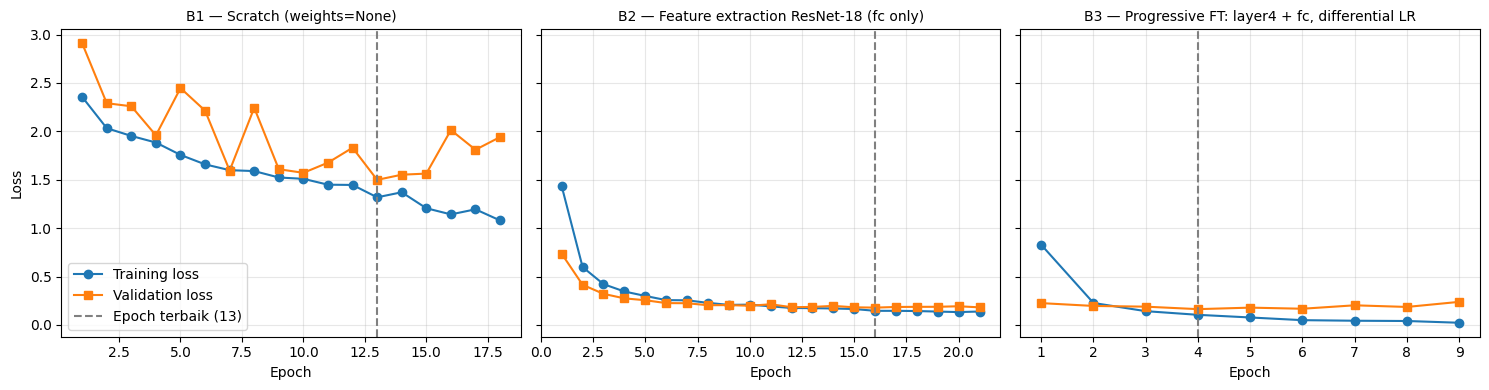

In [9]:
# C1 — Kurva training loss vs. validation loss (B1, B2, B3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, c in zip(axes, ["B1", "B2", "B3"]):
    h = histories[c]; best = int(log_df.loc[log_df.Condition == c, "Converged_Epoch"].iloc[0])
    ax.plot(h.Epoch, h.Train_Loss, marker="o", label="Training loss")
    ax.plot(h.Epoch, h.Val_Loss, marker="s", label="Validation loss")
    ax.axvline(best, color="gray", ls="--", label=f"Epoch terbaik ({best})")
    ax.set_title(f"{c} — {STRATEGY[c]}", fontsize=10); ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
axes[0].set_ylabel("Loss"); axes[0].legend()
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

,Condition,Converged_Epoch,Train_Acc_Clean,Val_Acc,Gen_Gap,Test_Acc,Test_Macro_F1
2,B3,4,0.9848,0.9394,0.0455,0.9396,0.9399
3,B4_NoAug,4,1.0000,0.9495,0.0505,0.9396,0.9399
4,B4_Aug,4,0.9848,0.9394,0.0455,0.9396,0.9399


Selisih NoAug - Aug  |  Val_Acc: +0.0101  |  Macro F1: +0.0000  |  Gen_Gap NoAug vs Aug: 0.0505 vs 0.0455
Cek reproduksibilitas B3 vs B4_Aug (konfigurasi sama): Val_Acc 0.9394 vs 0.9394


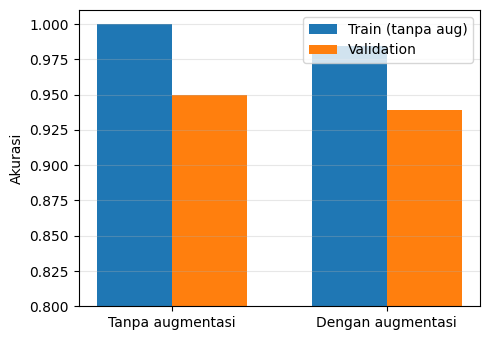

In [10]:
# C2.3 — Uji kontrol augmentasi (B4): celah train vs. validation
b4 = log_df[log_df.Condition.isin(["B3", "B4_NoAug", "B4_Aug"])][
    ["Condition", "Converged_Epoch", "Train_Acc_Clean", "Val_Acc", "Gen_Gap", "Test_Acc", "Test_Macro_F1"]]
display(b4)
d = log_df.set_index("Condition")
print(f"Selisih NoAug - Aug  |  Val_Acc: {d.loc['B4_NoAug','Val_Acc']-d.loc['B4_Aug','Val_Acc']:+.4f}"
      f"  |  Macro F1: {d.loc['B4_NoAug','Test_Macro_F1']-d.loc['B4_Aug','Test_Macro_F1']:+.4f}"
      f"  |  Gen_Gap NoAug vs Aug: {d.loc['B4_NoAug','Gen_Gap']:.4f} vs {d.loc['B4_Aug','Gen_Gap']:.4f}")
print(f"Cek reproduksibilitas B3 vs B4_Aug (konfigurasi sama): Val_Acc {d.loc['B3','Val_Acc']} vs {d.loc['B4_Aug','Val_Acc']}")

fig, ax = plt.subplots(figsize=(5, 3.5))
x = np.arange(2); w = 0.35
ax.bar(x - w/2, [d.loc["B4_NoAug", "Train_Acc_Clean"], d.loc["B4_Aug", "Train_Acc_Clean"]], w, label="Train (tanpa aug)")
ax.bar(x + w/2, [d.loc["B4_NoAug", "Val_Acc"], d.loc["B4_Aug", "Val_Acc"]], w, label="Validation")
ax.set_xticks(x); ax.set_xticklabels(["Tanpa augmentasi", "Dengan augmentasi"])
ax.set_ylim(0.8, 1.01); ax.set_ylabel("Akurasi"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("augmentation_gap.png", dpi=150); plt.show()

Model terbaik: B5 | jumlah salah: 14 / 298


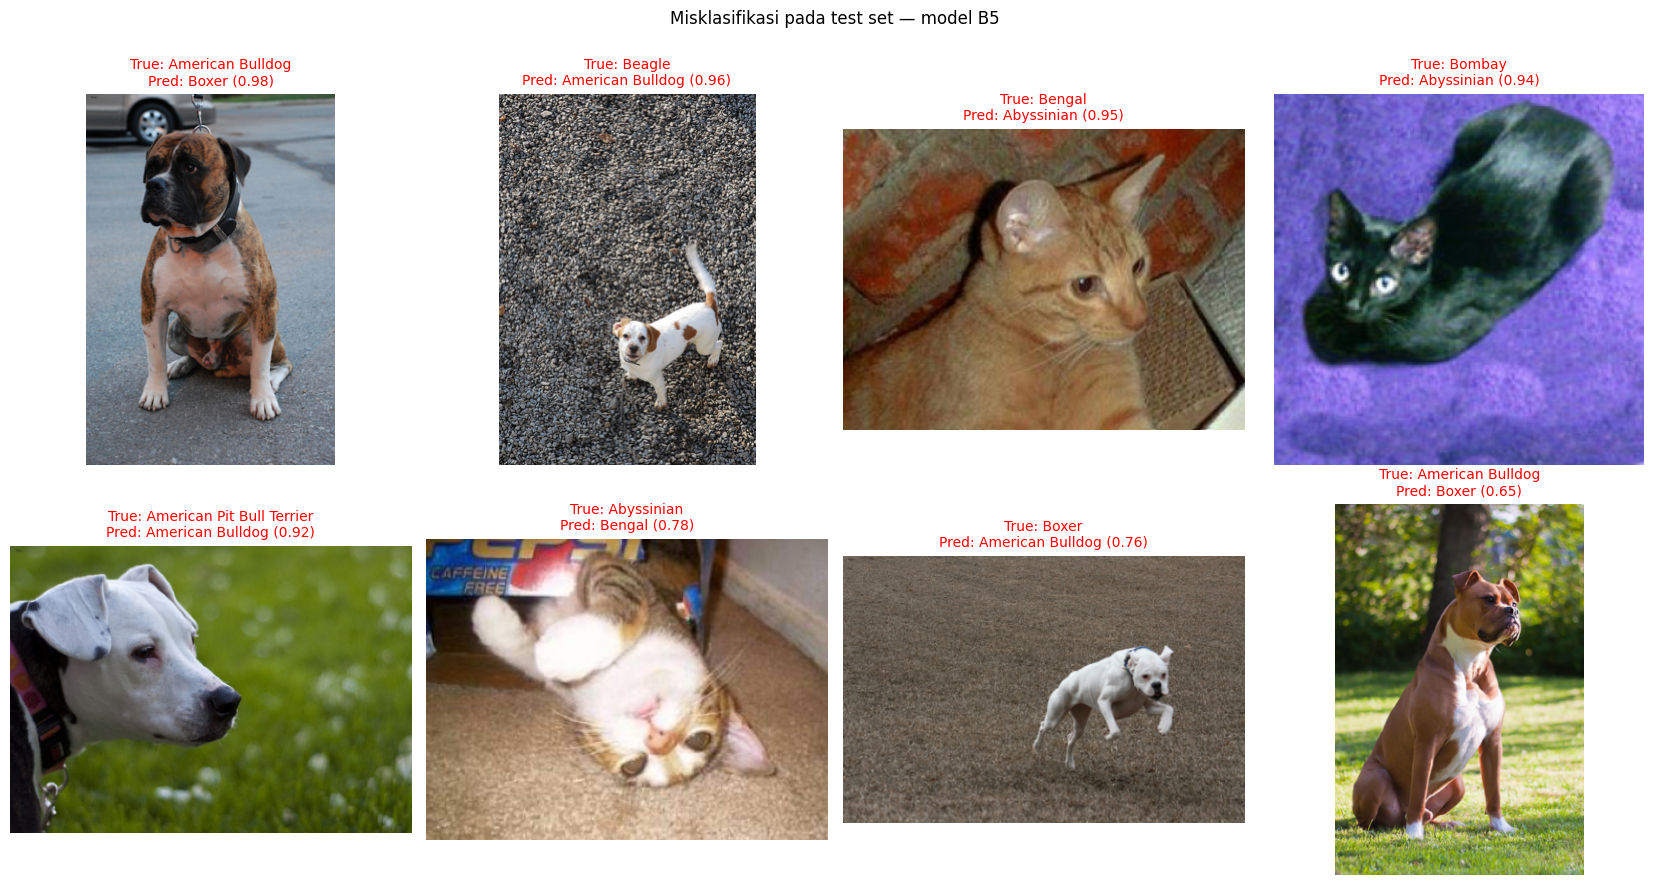

,Test_Idx,Image_File,True,Pred,Confidence,Prob_True_Class,Hipotesis
0,280,american_bulldog_54.jpg,American Bulldog,Boxer,0.9810,0.0168,
1,7,beagle_189.jpg,Beagle,American Bulldog,0.9569,0.0193,
2,272,Bengal_134.jpg,Bengal,Abyssinian,0.9465,0.0529,
3,114,Bombay_160.jpg,Bombay,Abyssinian,0.9411,0.0144,
4,25,american_pit_bull_terrier_27.jpg,American Pit Bull Terrier,American Bulldog,0.9208,0.0568,
5,190,Abyssinian_215.jpg,Abyssinian,Bengal,0.7827,0.1704,
6,112,boxer_18.jpg,Boxer,American Bulldog,0.7555,0.2109,
7,256,american_bulldog_102.jpg,American Bulldog,Boxer,0.6492,0.0299,


In [11]:
# C3 — Failure analysis pada model terbaik (berdasarkan Test Macro F1)
FAIL_SELECT = "highest_conf"
N_SHOW = 8

best_code = log_df.loc[log_df["Test_Macro_F1"].idxmax(), "Condition"]
art = artifacts[best_code]
wrong = np.where(art["preds"] != art["targets"])[0]
conf = art["probs"][wrong, art["preds"][wrong]]
print(f"Model terbaik: {best_code} | jumlah salah: {len(wrong)} / {len(art['targets'])}")

if FAIL_SELECT == "highest_conf": order = wrong[np.argsort(-conf)]
elif FAIL_SELECT == "lowest_conf": order = wrong[np.argsort(conf)]
else: order = np.random.RandomState(SEED).permutation(wrong)
show = order[:min(N_SHOW, len(order))]
if len(show) < 5: warnings.warn("Kesalahan < 5; soal meminta 5-8 sampel.")

ncols = 4; nrows = int(np.ceil(len(show) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.4 * nrows)); axes = np.atleast_1d(axes).ravel()
rec = []
for ax in axes: ax.axis("off")
for ax, k in zip(axes, show):
    t, p = int(art["targets"][k]), int(art["preds"][k]); cf = float(art["probs"][k, p])
    ax.imshow(pil_imgs[test_i[k]])
    ax.set_title(f"True: {CLASS_NAMES[t]}\nPred: {CLASS_NAMES[p]} ({cf:.2f})", color="red", fontsize=10)
    rec.append({"Test_Idx": int(k), "Image_File": paths[test_i[k]].name, "True": CLASS_NAMES[t], "Pred": CLASS_NAMES[p],
                "Confidence": round(cf, 4), "Prob_True_Class": round(float(art["probs"][k, t]), 4), "Hipotesis": ""})
plt.suptitle(f"Misklasifikasi pada test set — model {best_code}", y=1.0)
plt.tight_layout(); plt.savefig("failure_analysis.png", dpi=150); plt.show()
fail_df = pd.DataFrame(rec); fail_df.to_csv("failure_analysis.csv", index=False); display(fail_df)

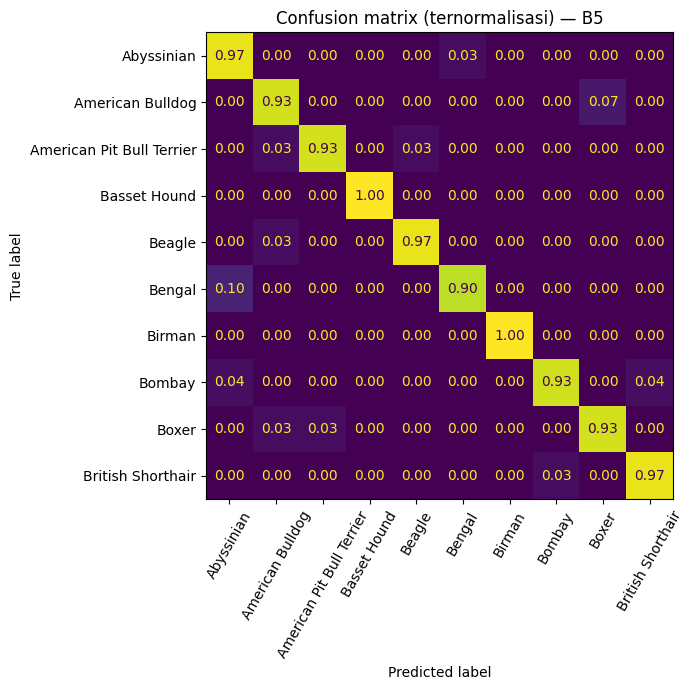

In [12]:
# Confusion matrix model terbaik
cm = confusion_matrix(art["targets"], art["preds"], labels=range(NUM_CLASSES), normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, xticks_rotation=60, colorbar=False, values_format=".2f")
ax.set_title(f"Confusion matrix (ternormalisasi) — {best_code}")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

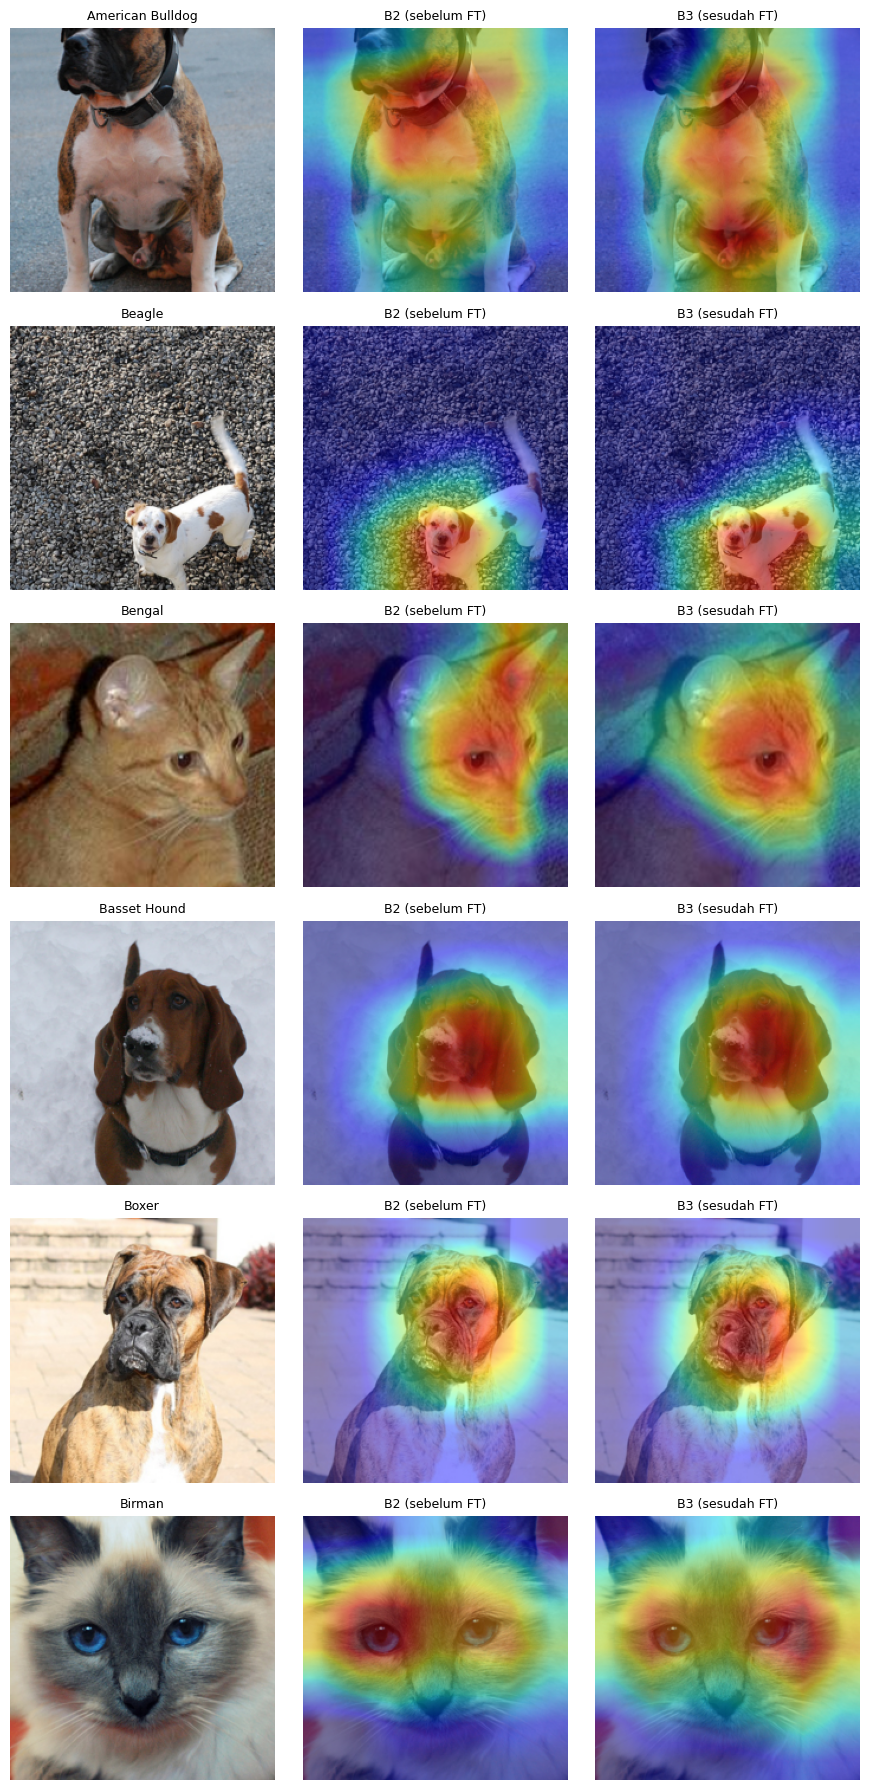

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [13]:
# C5 — Grad-CAM pada layer4: sebelum vs. sesudah fine-tuning
def gradcam(model, x, target):
    model.eval(); store = {}
    def fh(m, i, o): o.retain_grad(); store["a"] = o
    h = model.layer4.register_forward_hook(fh)
    x = x.clone().requires_grad_(True)
    with torch.enable_grad():
        out = model(x); model.zero_grad(); out[0, target].backward()
    h.remove()
    a, g = store["a"], store["a"].grad
    cam = torch.relu((g.mean(dim=(2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

m_before, m_after = artifacts["B2"]["model"].to(device), artifacts["B3"]["model"].to(device)
correct_idx = np.where(art["preds"] == art["targets"])[0]
pick = list(show[:3]) + list(correct_idx[:3])
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(len(pick), 3, figsize=(9, 3 * len(pick)))
for r, k in enumerate(pick):
    xk = eval_transforms(pil_imgs[test_i[k]]).unsqueeze(0).to(device); t = int(art["targets"][k])
    img = (xk[0].cpu() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"{CLASS_NAMES[t]}", fontsize=9)
    for c, (mdl, name) in enumerate([(m_before, "B2 (sebelum FT)"), (m_after, "B3 (sesudah FT)")], start=1):
        axes[r, c].imshow(img); axes[r, c].imshow(gradcam(mdl, xk, t), cmap="jet", alpha=0.45)
        axes[r, c].set_title(name, fontsize=9)
    for c in range(3): axes[r, c].axis("off")
plt.tight_layout(); plt.savefig("gradcam_before_after.png", dpi=150); plt.show()
artifacts["B2"]["model"].to("cpu"); artifacts["B3"]["model"].to("cpu")